# Analiza efektywności wykorzystania systemów rowerów miejskich: metody statystyczne i wizualizacja danych
### Praca inżynierska na kierunku Analiza Danych

Marcin Bereza

Nr albumu: 402790

---

## Wczytywanie danych i podstawwowe statystkyki
### Ładowanie bibliotek

In [3]:
from matplotlib import pyplot as plt
import pandas as pd
import numpy as np
import os
import re
import json
import datetime
from itertools import combinations
import math

### Ładowanie i łączenie zbiorów danych w jedną tabele

In [3]:
def get_file_paths(directory: str) -> list[str]:
    """Zwraca listę plików z wybranego katalogu."""
    file_paths: list[str] = []
    for file in os.listdir(directory):
        if file.startswith('.'): break
        file_path = os.path.join(directory, file)
        
        if not os.path.isdir(file_path):
            file_paths.append(file_path)
    return file_paths

def load_data(filepaths):
    data = []
    
    for filepath in filepaths:
        df = pd.read_csv(filepath, encoding='utf-8')
        data.append(df)
        
    return pd.concat(data, ignore_index=True)

In [4]:
przejazdy = get_file_paths('Przejazdy')
df = load_data(przejazdy)

### Statystyki zbioru

In [4]:
df = pd.read_csv('.\\Przejazdy\\historia_przejazdow_2021-06.csv')

Wyświetlenie rekordów

In [8]:
display(df.head())
df.info()

,UID wynajmu,Numer roweru,Data wynajmu,Data zwrotu,Stacja wynajmu,Stacja zwrotu,Czas trwania
0,117550772,650958,2021-05-31 23:56:02,2021-06-01 00:00:14,Plac Dominikański (Galeria Dominikańska),Drobnera / Plac Bema,5
1,117550680,651077,2021-05-31 23:52:25,2021-06-01 00:00:19,Rynek,Joliot-Curie (Uwr),8
2,117550567,57642,2021-05-31 23:47:00,2021-06-01 00:00:36,Rondo Reagana,Nowowiejska / Wyszyńskiego,14
3,117550568,57769,2021-05-31 23:47:02,2021-06-01 00:00:36,Rondo Reagana,Nowowiejska / Wyszyńskiego,14
4,117550652,650203,2021-05-31 23:51:08,2021-06-01 00:00:44,Wróblewskiego (Teki),"Olszewskiego, pętla tramwajowa",10


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 306899 entries, 0 to 306898
Data columns (total 7 columns):
 #   Column          Non-Null Count   Dtype 
---  ------          --------------   ----- 
 0   UID wynajmu     306899 non-null  int64 
 1   Numer roweru    306899 non-null  int64 
 2   Data wynajmu    306899 non-null  object
 3   Data zwrotu     306899 non-null  object
 4   Stacja wynajmu  306899 non-null  object
 5   Stacja zwrotu   306899 non-null  object
 6   Czas trwania    306899 non-null  int64 
dtypes: int64(3), object(4)
memory usage: 16.4+ MB


## Czyszczenie zbioru

Usuwamy wszystki spacje i przecinki z początku i końca każdego rekordu w kolumnach:
- Stacja wynajmu
- Stacja zwrotu

In [5]:
df = df.replace('\xa0', '', regex=True)
df['Stacja wynajmu'] = df['Stacja wynajmu'].map(lambda x: x.strip())
df['Stacja wynajmu'] = df['Stacja wynajmu'].map(lambda x: x.strip(','))

df['Stacja zwrotu'] = df['Stacja zwrotu'].map(lambda x: x.strip())
df['Stacja zwrotu'] = df['Stacja zwrotu'].map(lambda x: x.strip(','))

Usuwamy pierwszą kolumne, która zawiera id wypożyczenia

In [6]:
df = df.drop(df.columns[0], axis=1)

Usuwamy rekordy zaczynające się od kropki.

In [7]:
df = df[~df['Stacja wynajmu'].str.startswith('.')]
df = df[~df['Stacja zwrotu'].str.startswith('.')]

Usuwamy rekordy dla których "Stacja wynajmu" / "Stacja zwrotu" posiada wartość "Poza stacją".

In [8]:
df = df[df['Stacja wynajmu'] != 'Poza stacją']
df = df[df['Stacja zwrotu'] != 'Poza stacją']

Usuwamy rekordy mające taką samą stacje wynajmu co stajca zwrotu, jeżelli czas trwania był krótszy niż pięć minut.

In [9]:
df = df[~((df['Stacja wynajmu'] == df['Stacja zwrotu']) & (df['Czas trwania'] < 5))]

In [129]:
df.head()

,Numer roweru,Data wynajmu,Data zwrotu,Stacja wynajmu,Stacja zwrotu,Czas trwania
0,650958,2021-05-31 23:56:02,2021-06-01 00:00:14,Plac Dominikański (Galeria Dominikańska),Drobnera / Plac Bema,5
1,651077,2021-05-31 23:52:25,2021-06-01 00:00:19,Rynek,Joliot-Curie (Uwr),8
2,57642,2021-05-31 23:47:00,2021-06-01 00:00:36,Rondo Reagana,Nowowiejska / Wyszyńskiego,14
3,57769,2021-05-31 23:47:02,2021-06-01 00:00:36,Rondo Reagana,Nowowiejska / Wyszyńskiego,14
4,650203,2021-05-31 23:51:08,2021-06-01 00:00:44,Wróblewskiego (Teki),"Olszewskiego, pętla tramwajowa",10


In [130]:
df.shape

(244380, 6)

#### Obserwacje odstające
Odrzucanie rekordów dla których czas trwania przekracza 1.5 krotności rozstępu między kwartylowego.

Przedział: (-7.0, 33.0)


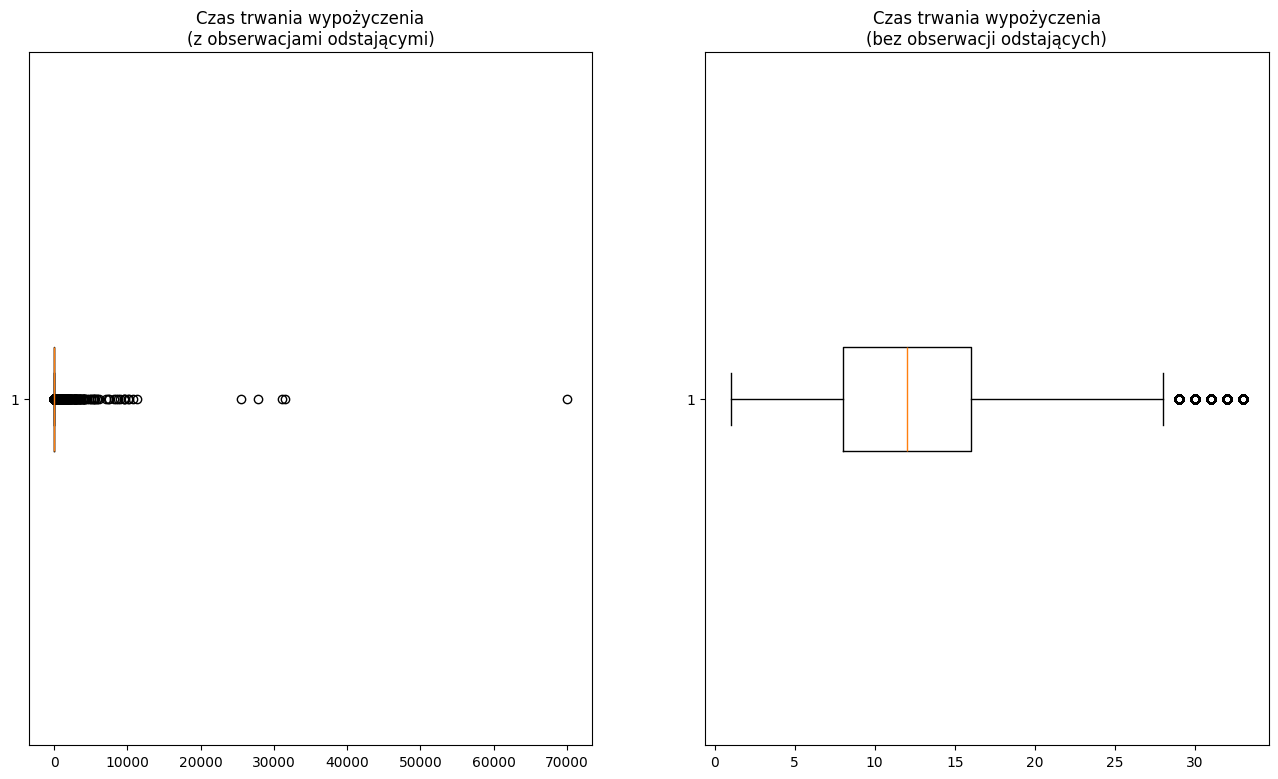

In [10]:
fig, axs = plt.subplots(1, 2, figsize=(16,9))
axs[0].boxplot(df['Czas trwania'], vert=False)
axs[0].set_title('Czas trwania wypożyczenia\n(z obserwacjami odstającymi)')

Q1 = df['Czas trwania'].quantile(0.25)
Q3 = df['Czas trwania'].quantile(0.75)
IQR = Q3 - Q1
threshold = 1.5
print(f'Przedział: {float(Q1 - threshold * IQR), float(Q3 + threshold * IQR)}')
df = df[(df['Czas trwania'] >= Q1 - threshold * IQR) & (df['Czas trwania'] <= Q3 + threshold * IQR)]

axs[1].boxplot(df['Czas trwania'], vert=False)
axs[1].set_title('Czas trwania wypożyczenia\n(bez obserwacji odstających)')

plt.show()

In [132]:
df.shape

(221951, 6)

<0, 5) 9967
<5, 10) 68495
<10, 15) 69777
<15, 20) 45566
<20, 25) 16166
<25, 30) 7672
<30, 35) 4308


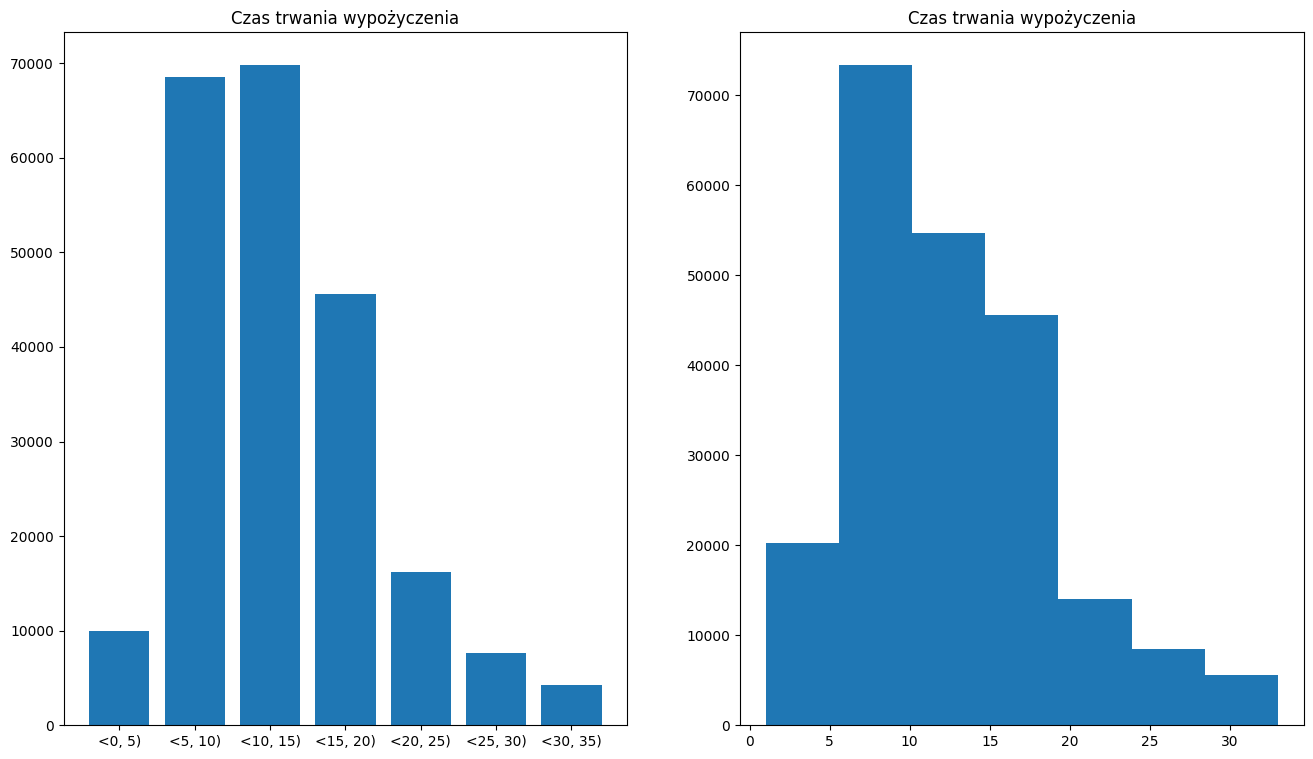

In [15]:
times = []
count = []
przedział = 5

for i, time in enumerate(range(0, df['Czas trwania'].max(), przedział),0):
    times.append(f'<{time}, {time+przedział})')
    count.append(sum((df['Czas trwania']>=time) & (df['Czas trwania']<time+przedział)))
    
    print(times[i], count[i])
    

fig, axs = plt.subplots(1, 2, figsize=(16,9))
axs[0].bar(times, count)
axs[0].set_title('Czas trwania wypożyczenia')

axs[1].hist(df['Czas trwania'], bins=7)
axs[1].set_title('Czas trwania wypożyczenia')
plt.show()

## Pobieranie lokalizacji stacji rowerowych
Wykorzystując funkcję web scraping z excela / power bi można zaciągnąć dane z wybranej przez siebie strony internetwej. Pobrałem lokalizację stacji ze strony: https://wroclawskirower.pl/mapa-stacji/.

Dane aktualizowane są w trybie ciągłym z racji, że interesuje mnie tylko ich położenie pozbywam się informacji o aktualnej liczbie rowerów i numerów dostepnych rowerów. Pozostawiam numer stacji i liczbę stojakw. Może się jeszcze przyda w przewidywaniu wykorzystania stacji.

Korzystając z ciągu $a_n = \frac{n(n-1)}{2}$ dla $a_{241} = 28\space920$ możliwych kombinacji stacji. Stworzymy tabele zawierające je wszystkie i obliczbymy odległości między nimy, a nastepnie dodamy do pierwotnego zestawienia i obliczbymy prędkość podróży rowerzysty.

Jest to relacja symetryczna i przeciwzwrotna.

In [2]:
loc = pd.read_excel('Lok.xlsx')
loc

NameError: name 'pd' is not defined

In [12]:
stacje_bez_współrzędnych = []

for place in list(pd.unique(df['Stacja wynajmu'])):
    if place not in list(loc.iloc[:,1]):
        stacje_bez_współrzędnych.append(place)

for place in list(pd.unique(df['Stacja zwrotu'])):
    if place not in list(loc.iloc[:,1]):
        stacje_bez_współrzędnych.append(place)

print('\n'.join(stacje_bez_współrzędnych))

Powstańców Śląskich (Arkady Wrocławskie)
Plac Staszica
Kurkowa / Dubois
Popowice
Walońska (Angel Poland Group)
Bardzka (cmentarz)
Świeradowska (Ferio Gaj)
Rogowska/Sukielicka
Popowicka
Ślężna / Skierniewicka
Radeckiego / Marcinkowskiego (Uniw. Medyczny - CNIM)
Traktatowa (przystanek kolejowy)
Świeradowska (Ferio Gaj)
Plac Staszica
Popowice
Ślężna / Skierniewicka
Powstańców Śląskich (Arkady Wrocławskie)
Walońska (Angel Poland Group)
Rogowska/Sukielicka
Bardzka (cmentarz)
Kurkowa / Dubois
Popowicka
Radeckiego / Marcinkowskiego (Uniw. Medyczny - CNIM)
Traktatowa (przystanek kolejowy)
MAHLE
Botaniczna (Ogród botaniczny - Mini ZOO)
Centrum Przesiadkowe


In [1]:
from geopy.geocoders import Nominatim
geolocator = Nominatim(user_agent="geoapiExercise")
locations = []

for adress in stacje_bez_współrzędnych:
    location = geolocator.geocode(''.join([adress, ', Wrocław']))
    locations.append([adress, location.latitude, location.longitude]) if location else print(adress)

NameError: name 'stacje_bez_współrzędnych' is not defined

In [16]:
locations

[['Plac Staszica', 51.122081, 17.0307755],
 ['Kurkowa / Dubois', 51.1181897, 17.028858],
 ['Popowice', 51.1241447, 16.9878358],
 ['Bardzka (cmentarz)', 51.0723883, 17.0528743],
 ['Świeradowska (Ferio Gaj)', 51.0769164, 17.0414695],
 ['Popowicka', 51.1259449, 17.0008975],
 ['Ślężna / Skierniewicka', 51.0771499, 17.0182684],
 ['Traktatowa (przystanek kolejowy)', 51.1124539, 16.9736001],
 ['Świeradowska (Ferio Gaj)', 51.0769164, 17.0414695],
 ['Plac Staszica', 51.122081, 17.0307755],
 ['Popowice', 51.1241447, 16.9878358],
 ['Ślężna / Skierniewicka', 51.0771499, 17.0182684],
 ['Bardzka (cmentarz)', 51.0723883, 17.0528743],
 ['Kurkowa / Dubois', 51.1181897, 17.028858],
 ['Popowicka', 51.1259449, 17.0008975],
 ['Traktatowa (przystanek kolejowy)', 51.1124539, 16.9736001]]

## Lenght matrix

In [30]:
def haversine(lat1, lon1, lat2, lon2):
    lat1 = math.radians(lat1)
    lon1 = math.radians(lon1)
    lat2 = math.radians(lat2)
    lon2 = math.radians(lon2)
    
    dlat = lat2 - lat1
    dlon = lon2 - lon1
    a = math.sin(dlat/2)**2 + \
        math.cos(lat1)*math.cos(lat2) * \
        math.sin(dlon/2)**2
    R = 6371.0
    distance = 2 * R * math.asin(math.sqrt(a))
    return distance


def create_station_combinations(stations):
    combinations_list = []
    for (i1, row1), (i2, row2) in combinations(stations.iterrows(), 2):
        combination = {
            'station1': row1['The name of the station'],
            'station2': row2['The name of the station'],
            'distance': haversine(row1['Latidude'],row1['Longitude'],row2['Latidude'],row2['Longitude'])
        }
        combinations_list.append(combination)
    return pd.DataFrame(combinations_list)


dist = create_station_combinations(loc.iloc[:,[1,3,4]])

dist.sort_values('distance', ascending=False)

,station1,station2,distance
25356,Strachocińska / Wieśniacza,Prochowicka / Dolnobrzeska,19.979058
25364,Strachocińska / Wieśniacza,Średzka / Dolnobrzeska,19.754914
25386,Strachocińska / Wieśniacza,"Wrocław Leśnica, stacja kolejowa",19.734688
25703,Prochowicka / Dolnobrzeska,Ziemniaczana/Boiskowa,19.546758
15881,Leśnica - pętla tramwajowa,Strachocińska / Wieśniacza,19.361239
...,...,...,...
5625,Janiszewskiego (PWr),Norwida / Wyspiańskiego (PWr),0.233610
8926,Stacyjna (Dworzec Mikołajów),Legnicka / Zachodnia,0.230533
10439,Joliot-Curie (Uwr),Plac Grunwaldzki / Polaka,0.202852
7878,Plac Legionów,Piłsudskiego 13 od Jump Hall,0.126382


In [46]:
def find_distance(rent_station, return_station):
    for i, row in dist.iterrows():
        if (row['station1'] == rent_station and row['station2'] == return_station) or \
            (row['station1'] == return_station and row['station2'] == rent_station):
                return row['distance']
    return None


df['dist'] = df.apply(lambda row: find_distance(row['Stacja wynajmu'], row['Stacja zwrotu']), axis=1)

C:\Users\bereZi\AppData\Local\Temp\ipykernel_5240\3877443323.py:10: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df2['dist'] = df2.apply(lambda row: find_distance(row['Stacja wynajmu'], row['Stacja zwrotu']), axis=1)


,Numer roweru,Data wynajmu,Data zwrotu,Stacja wynajmu,Stacja zwrotu,Czas trwania,dist
0,650958,2021-05-31 23:56:02,2021-06-01 00:00:14,Plac Dominikański (Galeria Dominikańska),Drobnera / Plac Bema,5,1.066984
1,651077,2021-05-31 23:52:25,2021-06-01 00:00:19,Rynek,Joliot-Curie (Uwr),8,1.576367
2,57642,2021-05-31 23:47:00,2021-06-01 00:00:36,Rondo Reagana,Nowowiejska / Wyszyńskiego,14,1.284909
3,57769,2021-05-31 23:47:02,2021-06-01 00:00:36,Rondo Reagana,Nowowiejska / Wyszyńskiego,14,1.284909
4,650203,2021-05-31 23:51:08,2021-06-01 00:00:44,Wróblewskiego (Teki),"Olszewskiego, pętla tramwajowa",10,1.689139
...,...,...,...,...,...,...,...
93,650421,2021-06-01 00:26:07,2021-06-01 00:39:35,Piławska,al. Armii Krajowej / Borowska,14,1.361972
94,650129,2021-06-01 00:30:30,2021-06-01 00:40:03,Plac Dominikański (Galeria Dominikańska),Promenady Wrocławskie,10,2.352055
97,650233,2021-06-01 00:36:39,2021-06-01 00:40:29,Plac Uniwersytecki (UWr),Plac Staszica,4,NaN
98,651124,2021-06-01 00:28:35,2021-06-01 00:42:14,Reymonta / Kleczkowska,Zaporoska / Grabiszyńska,14,2.937544


## Dzień tygodnia

In [17]:
dni = ['Pon', 'Wt', 'Śr', 'Czw', 'Pt', 'Sob', 'Niedz']

df['Data wynajmu']      = pd.to_datetime(df['Data wynajmu'])
df['Dzień tygodnia']    = df['Data wynajmu'].dt.dayofweek.apply(lambda x: dni[x])
df['Rok wynajmu']       = df['Data wynajmu'].dt.year
df['Miesiąc wynajmu']   = df['Data wynajmu'].dt.month
df['Dzień wynajmu']     = df['Data wynajmu'].dt.day
df['Godzina wynajmu']   = df['Data wynajmu'].dt.hour
df['Minuta wynajmu']    = df['Data wynajmu'].dt.minute

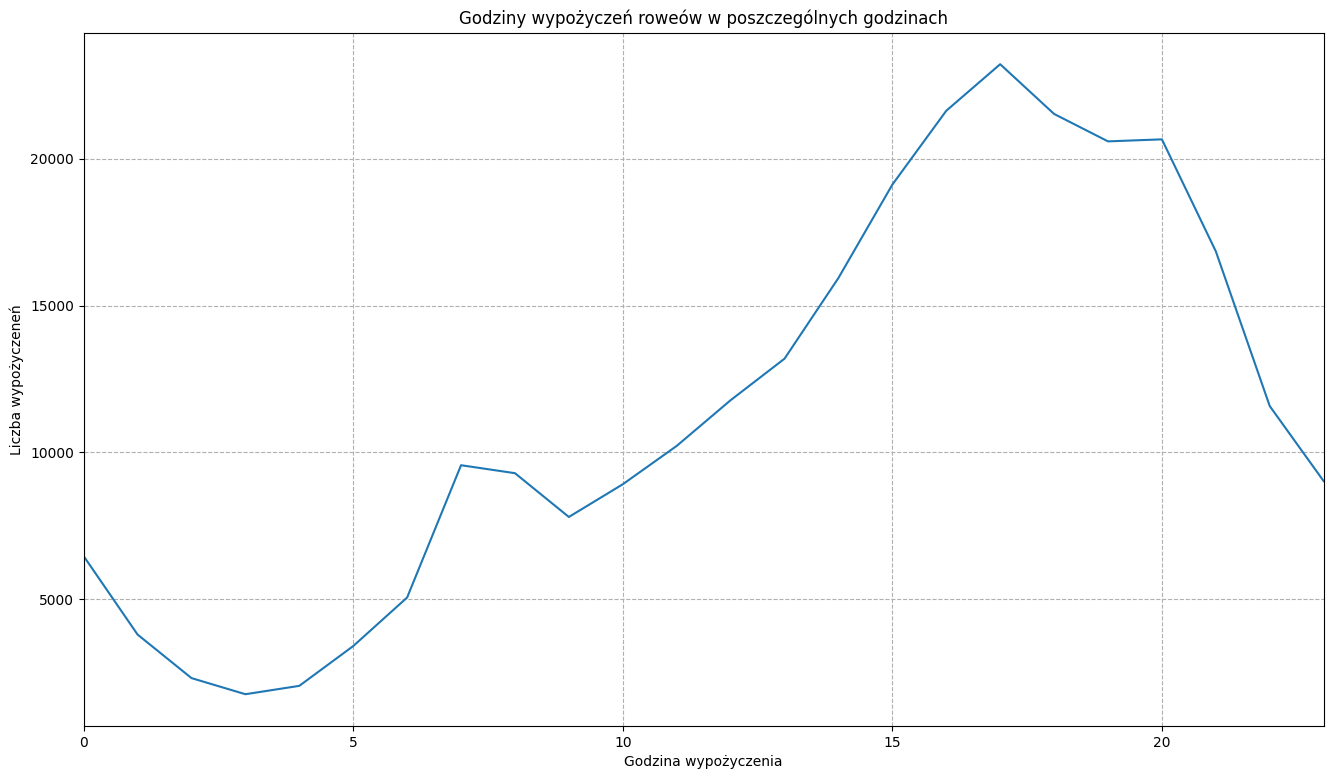

In [92]:
fig, axs = plt.subplots(figsize=(16,9))

grupy_godziny = df.groupby(['Godzina wynajmu']).size()

axs.set_xlim(0, 23)
axs.plot(grupy_godziny)
axs.set_title('Godziny wypożyczeń roweów w poszczególnych godzinach')
plt.xlabel('Godzina wypożyczenia')
plt.ylabel('Liczba wypożyczeneń')
plt.grid(True, linestyle='--')
plt.show()

In [96]:
df.groupby('Godzina wynajmu').size()

Godzina wynajmu
0      6471
1      3801
2      2319
3      1770
4      2055
5      3409
6      5062
7      9564
8      9293
9      7803
10     8916
11    10221
12    11777
13    13190
14    15937
15    19114
16    21628
17    23212
18    21520
19    20586
20    20655
21    16843
22    11577
23     9023
dtype: int64